# Лабораторная работа №3. Оптимизация гиперпараметров

Предсказываем качество красного и белого вина по 11 физико-химическим признакам и типу вина (Wine Quality, UCI).

Основная модель — **XGBoost**, дополнительное исследование — **CatBoost**. Для каждой модели сравниваем Grid Search, Random Search и байесовскую оптимизацию Optuna. Поиск проходит в два этапа: широкая область, затем уточнение вокруг лучшего результата.

Выбираем параметры по **RMSE на кросс-валидации**. На отложенной test-выборке считаем RMSE и MAE. Недообучение и переобучение оцениваем по кривым обучения.

Расчёт выполняется на объединённом датасете. Завершённые проверки сохраняются в Google Drive.


## 1. Подготовка

Выберите T4 GPU. После разрешения доступа к Drive завершённые CV-проверки, состояние Optuna и точки кривых обучения сохраняются автоматически.

После обрыва выполните ноутбук сначала: он загрузит готовое и продолжит расчёт. Может повториться только проверка, которая не успела сохраниться. Эта папка checkpoint предназначена для текущих данных, разбиений и настроек моделей; при их изменении нужна новая папка.


In [ ]:
%pip -q install xgboost catboost optuna scikit-learn

In [ ]:
import time

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from catboost import CatBoostRegressor
from IPython.display import Markdown, display
from scipy.stats import loguniform, randint
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    ParameterGrid,
    ParameterSampler,
)
from xgboost import XGBRegressor

SEED = 42

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 115, 'axes.titlesize': 12})
optuna.logging.set_verbosity(optuna.logging.WARNING)


import pickle
import subprocess
from pathlib import Path
from google.colab import drive

print(subprocess.check_output(
    ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
    text=True,
))
drive.mount('/content/drive')

CHECKPOINT_DIR = Path('/content/drive/MyDrive/MAI_lab03_red_white_2026_10_29')
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def load_checkpoint(name, default):
    path = CHECKPOINT_DIR / f'{name}.pkl'
    if not path.exists():
        return default
    with path.open('rb') as file:
        return pickle.load(file)


def save_checkpoint(name, value):
    path = CHECKPOINT_DIR / f'{name}.pkl'
    temporary = path.with_suffix('.tmp')
    with temporary.open('wb') as file:
        pickle.dump(value, file)
    temporary.replace(path)


save_checkpoint('write_check', 'ok')
if load_checkpoint('write_check', None) != 'ok':
    raise RuntimeError('Не удалось проверить сохранение в Google Drive.')
print('Прогресс сохраняется в:', CHECKPOINT_DIR)


Tesla T4, 15360 MiB

Mounted at /content/drive
Прогресс сохраняется в: /content/drive/MyDrive/MAI_lab03_red_white_2026_10_29


## 2. Данные и разбиение

Используем красные и белые вина из [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality). Целевая переменная — `quality`. Масштабирование признаков деревьям не требуется; тип вина задаём признаком `is_red`.

В данных есть одинаковые наборы признаков. Объединяем их в группы и целиком относим к одной части: это предотвращает попадание одинаковых объектов в train и test либо train и validation. Для test откладываем 20% групп. Данные не удаляем и не усредняем.


Всего 6497 строк; train=5210, test=1287; уникальных наборов признаков=5320.


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red
count,5210.000,5210.000,5210.000,5210.000,5210.000,5210.000,5210.000,5210.000,5210.000,5210.000,5210.000,5210.000
mean,7.203,0.339,0.318,5.463,0.055,30.688,116.330,0.995,3.219,0.528,10.493,0.242
std,1.298,0.164,0.146,4.786,0.032,17.998,56.688,0.003,0.162,0.143,1.196,0.429
min,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,0.000
25%,6.400,0.230,0.250,1.800,0.038,17.000,78.000,0.992,3.110,0.430,9.500,0.000
50%,7.000,0.290,0.310,3.000,0.047,29.000,118.000,0.995,3.200,0.500,10.300,0.000
75%,7.700,0.400,0.390,8.100,0.064,41.500,157.000,0.997,3.320,0.600,11.300,0.000
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,1.980,14.900,1.000


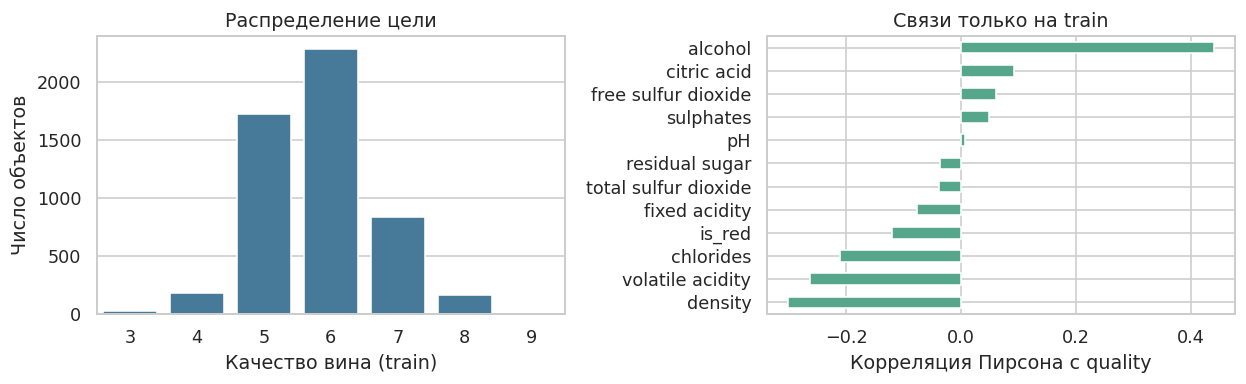

На train самая сильная по модулю линейная связь у **alcohol** (0.441). Это описательная ассоциация, а не причинный эффект. Редкие оценки представлены слабее центральных.

In [ ]:
URL_RED = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
URL_WHITE = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'

data_red = pd.read_csv(URL_RED, sep=';')
data_red['is_red'] = 1

data_white = pd.read_csv(URL_WHITE, sep=';')
data_white['is_red'] = 0

data = pd.concat([data_red, data_white], ignore_index=True)

features = data.drop(columns='quality')
groups, _ = pd.factorize(pd.MultiIndex.from_frame(features))

split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(split.split(features, groups=groups))

X_train = features.iloc[train_idx].to_numpy(dtype=np.float32)
y_train = data['quality'].iloc[train_idx].to_numpy(dtype=np.float64)
X_test = features.iloc[test_idx].to_numpy(dtype=np.float32)
y_test = data['quality'].iloc[test_idx].to_numpy(dtype=np.float64)
groups_train = groups[train_idx]

cv = GroupKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, groups=groups_train))


protocol = {
    'data': data.to_json(orient='split'),
    'train_idx': train_idx.tolist(),
    'test_idx': test_idx.tolist(),
    'cv_splits': [],
}
for fit_idx, valid_idx in cv_splits:
    protocol['cv_splits'].append((fit_idx.tolist(), valid_idx.tolist()))

if load_checkpoint('data_protocol', protocol) != protocol:
    raise ValueError('Данные или разбиения изменились. Выберите новую папку checkpoint.')
save_checkpoint('data_protocol', protocol)

print(
    f'Всего {len(data)} строк; train={len(train_idx)}, test={len(test_idx)}; '
    f'уникальных наборов признаков={len(np.unique(groups))}.'
)
display(features.iloc[train_idx].describe().round(3))

train_data = data.iloc[train_idx]
correlations = train_data.corr(numeric_only=True)['quality']
correlations = correlations.drop('quality').sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

sns.countplot(x=y_train.astype(int), ax=axes[0], color='#3a7ca5')
axes[0].set(
    xlabel='Качество вина (train)',
    ylabel='Число объектов',
    title='Распределение цели',
)

correlations.plot.barh(ax=axes[1], color='#55a68a')
axes[1].set(
    xlabel='Корреляция Пирсона с quality',
    title='Связи только на train',
)

plt.tight_layout()
plt.show()

strongest = correlations.abs().idxmax()
display(Markdown(
    f'На train самая сильная по модулю линейная связь у **{strongest}** '
    f'({correlations[strongest]:.3f}). Это описательная ассоциация, '
    'а не причинный эффект. Редкие оценки представлены слабее центральных.'
))


### Кросс-валидация и метрики

Все модели и методы используют **одни и те же три разбиения GroupKFold**. Параметры выбираем по среднему RMSE трёх folds; test до финальной оценки не используем. Многократный подбор по test сделал бы его оценку слишком оптимистичной.

RMSE сильнее штрафует крупные ошибки, MAE показывает среднее абсолютное отклонение. Обе метрики измеряются в баллах качества вина. Также сравниваем train RMSE и разброс RMSE между folds. Стандартное отклонение трёх оценок описывает разброс, но не является доверительным интервалом.

In [ ]:
FAMILIES = ['XGBoost', 'CatBoost']
BASE_PARAMS = {'n_estimators': 100, 'learning_rate': 0.10, 'max_depth': 3}


def make_model(family, params):
    n_estimators = int(params['n_estimators'])
    learning_rate = float(params['learning_rate'])
    max_depth = int(params['max_depth'])

    if family == 'XGBoost':
        return XGBRegressor(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=max_depth,
            objective='reg:squarederror',
            tree_method='hist',
            device='cuda',
            random_state=SEED,
            n_jobs=2,
            subsample=1.0,
            colsample_bytree=1.0,
            reg_lambda=1.0,
            min_child_weight=1,
            max_bin=256,
        )

    return CatBoostRegressor(
        iterations=n_estimators,
        learning_rate=learning_rate,
        depth=max_depth,
        loss_function='RMSE',
        task_type='GPU',
        devices='0',
        random_seed=SEED,
        thread_count=2,
        l2_leaf_reg=3.0,
        bootstrap_type='Bayesian',
        random_strength=1.0,
        border_count=128,
        verbose=False,
        allow_writing_files=False,
    )


def evaluate(family, params, checkpoint=None):
    if checkpoint is not None:
        saved = load_checkpoint(checkpoint, None)
        if saved is not None:
            return saved

    train_scores = []
    valid_scores = []
    valid_mae = []

    for fit_idx, valid_idx in cv_splits:
        model = make_model(family, params)
        model.fit(X_train[fit_idx], y_train[fit_idx])

        train_pred = model.predict(X_train[fit_idx])
        valid_pred = model.predict(X_train[valid_idx])

        train_scores.append(root_mean_squared_error(y_train[fit_idx], train_pred))
        valid_scores.append(root_mean_squared_error(y_train[valid_idx], valid_pred))
        valid_mae.append(mean_absolute_error(y_train[valid_idx], valid_pred))

    result = {
        'params': params,
        'train_rmse': np.mean(train_scores),
        'cv_rmse': np.mean(valid_scores),
        'cv_std': np.std(valid_scores, ddof=1),
        'fold_rmse': valid_scores,
        'fold_mae': valid_mae,
    }

    if checkpoint is not None:
        save_checkpoint(checkpoint, result)
    return result


baseline_results = {}
baseline_rows = []

for family in FAMILIES:
    result = evaluate(family, BASE_PARAMS, checkpoint=f'baseline_{family}')
    baseline_results[family] = result
    baseline_rows.append({
        'model': family,
        'params': result['params'],
        'CV_RMSE': result['cv_rmse'],
        'CV_std': result['cv_std'],
        'train_RMSE': result['train_rmse'],
    })

display(pd.DataFrame(baseline_rows))


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [18:27:42] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


,model,params,CV_RMSE,CV_std,train_RMSE
0,XGBoost,"{'n_estimators': 100, 'learning_rate': 0.1, 'm...",0.704673,0.015949,0.619396
1,CatBoost,"{'n_estimators': 100, 'learning_rate': 0.1, 'm...",0.709374,0.020085,0.667618


### Оценка времени

Перед большим поиском измерим время трёх конфигураций на первом fold. Это приблизительная оценка: скорость зависит от числа деревьев, их глубины и нагрузки на GPU.

Для каждого метода проверяем **64 + 105 = 169 конфигураций**. Всего для двух моделей и трёх методов — **1014 конфигураций и 3042 CV-обучения**. Кривые обучения и срезы параметров считаем отдельно. Early stopping и pruning не используем.

In [ ]:
pilot = load_checkpoint('pilot', None)
if pilot is None:
    pilot = []
    fit_idx, valid_idx = cv_splits[0]

    for family in FAMILIES:
        for n_estimators, max_depth in [(100, 3), (500, 5), (1000, 7)]:
            params = {
                'n_estimators': n_estimators,
                'learning_rate': 0.05,
                'max_depth': max_depth,
            }

            started = time.perf_counter()
            model = make_model(family, params)
            model.fit(X_train[fit_idx], y_train[fit_idx])
            model.predict(X_train[valid_idx])

            pilot.append({
                'family': family,
                'n_estimators': n_estimators,
                'learning_rate': 0.05,
                'max_depth': max_depth,
                'fit_seconds': time.perf_counter() - started,
            })
    save_checkpoint('pilot', pilot)

pilot_table = pd.DataFrame(pilot)
display(pilot_table.round(3))

for family in FAMILIES:
    part = pilot_table[pilot_table['family'] == family]
    minutes = part['fit_seconds'].median() * 169 * 3 * 3 / 60
    print(f'{family}: грубый ориентир на три метода — {minutes:.1f} мин.')


,family,n_estimators,learning_rate,max_depth,fit_seconds
0,XGBoost,100,0.05,3,0.369
1,XGBoost,500,0.05,5,1.472
2,XGBoost,1000,0.05,7,2.021
3,CatBoost,100,0.05,3,0.246
4,CatBoost,500,0.05,5,3.725
5,CatBoost,1000,0.05,7,12.073


XGBoost: грубый ориентир на три метода — 37.3 мин.
CatBoost: грубый ориентир на три метода — 94.4 мин.


## 3. Пространство параметров

| Параметр | Смысл | Широкая сетка |
|---|---|---|
| `n_estimators` (`iterations` в CatBoost) | Число деревьев | 100, 300, 600, 1000 |
| `learning_rate` | Вклад очередного дерева | 0.01, 0.03, 0.10, 0.20 |
| `max_depth` (`depth` в CatBoost) | Глубина дерева | 2, 4, 6, 8 |

Сначала Grid Search проверяет 64 комбинации. Затем уточняет область вокруг своего победителя: 7 значений числа деревьев, 5 значений шага и 3 глубины — ещё 105 комбинаций. Random Search и Optuna используют такие же бюджеты и уточняют область вокруг **своего** лучшего результата. Итоговый победитель выбирается среди обоих этапов.

Random Search и Optuna выбирают число деревьев и глубину из целых чисел, а `learning_rate` — непрерывно в логарифмическом масштабе. Границы берём из сетки. В уточнённый поиск первым включаем победителя широкого этапа. Остальные параметры моделей зафиксированы в `make_model`.

In [ ]:
COARSE_GRID = {
    'n_estimators': [100, 300, 600, 1000],
    'learning_rate': [0.01, 0.03, 0.10, 0.20],
    'max_depth': [2, 4, 6, 8],
}
N_COARSE = 64
N_FINE = 105


def fine_grid(params):
    n_estimators = int(params['n_estimators'])
    n_values = []

    for multiplier in np.linspace(0.6, 1.4, 7):
        value = int(round(n_estimators * multiplier / 10) * 10)
        n_values.append(value)

    # Сохраняем точное число деревьев победителя в середине сетки.
    n_values[3] = n_estimators

    rate_values = []
    for multiplier in [0.6, 0.8, 1.0, 1.2, 1.4]:
        rate_values.append(float(params['learning_rate']) * multiplier)

    depth = int(params['max_depth'])
    return {
        'n_estimators': sorted(set(n_values)),
        'learning_rate': rate_values,
        'max_depth': [depth - 1, depth, depth + 1],
    }


def random_space(grid):
    return {
        'n_estimators': randint(
            min(grid['n_estimators']), max(grid['n_estimators']) + 1,
        ),
        'learning_rate': loguniform(
            min(grid['learning_rate']), max(grid['learning_rate']),
        ),
        'max_depth': randint(min(grid['max_depth']), max(grid['max_depth']) + 1),
    }


def best_result(results):
    best = results[0]
    for result in results[1:]:
        if result['cv_rmse'] < best['cv_rmse']:
            best = result
    return best


def summarize_search(rows):
    seconds = 0
    for row in rows:
        seconds += row['search_seconds']

    return {
        'best': best_result(rows),
        'rows': rows,
        'seconds': seconds,
        'n_candidates': len(rows),
    }

## 4. Grid Search и Random Search

`ParameterGrid` создаёт все комбинации сетки, `ParameterSampler` — случайные комбинации из заданных распределений. Для каждой конфигурации выполняем одинаковую кросс-валидацию. Время измеряем отдельно для каждого метода.

In [ ]:
def evaluate_plan(family, method, stage, plan):
    checkpoint_name = f'{family}_{method}_{stage}'
    state = load_checkpoint(checkpoint_name, None)
    if state is None:
        rows = []
    else:
        if state['plan'] != plan:
            raise ValueError(f'План поиска изменился: {checkpoint_name}')
        rows = state['rows']
        if len(rows) > len(plan):
            raise ValueError(f'Лишние результаты в checkpoint: {checkpoint_name}')
        print(f'{family} {method} {stage}: восстановлено {len(rows)}/{len(plan)}')

    for params in plan[len(rows):]:
        started = time.perf_counter()
        result = evaluate(family, params)
        result['search_seconds'] = time.perf_counter() - started
        rows.append(result)
        save_checkpoint(checkpoint_name, {'plan': plan, 'rows': rows})
        if len(rows) % 10 == 0 or len(rows) == len(plan):
            print(f'{family} {method} {stage}: {len(rows)}/{len(plan)}')
    return rows


def run_grid_or_random(family, method):
    if method == 'Grid':
        coarse_plan = list(ParameterGrid(COARSE_GRID))
    else:
        coarse_plan = list(ParameterSampler(
            random_space(COARSE_GRID),
            n_iter=N_COARSE,
            random_state=SEED,
        ))

    coarse_rows = evaluate_plan(family, method, 'coarse', coarse_plan)
    coarse_best = best_result(coarse_rows)
    grid = fine_grid(coarse_best['params'])

    if method == 'Grid':
        fine_plan = list(ParameterGrid(grid))
    else:
        fine_plan = [coarse_best['params']]
        fine_plan.extend(ParameterSampler(
            random_space(grid),
            n_iter=N_FINE - 1,
            random_state=SEED + 1,
        ))

    fine_rows = evaluate_plan(family, method, 'fine', fine_plan)
    return summarize_search(coarse_rows + fine_rows)


## 5. Байесовская оптимизация Optuna

Используем **TPE**: он выбирает новые параметры с учётом результатов предыдущих проверок. Первые 10 trials — случайная разведка; `multivariate=True` учитывает совместное поведение параметров.

Для уточнённой области создаём новую `study` и первой проверяем лучшую конфигурацию широкого этапа. Затем выбираем лучший результат среди обоих этапов. Локальное уточнение не гарантирует нахождения глобального оптимума.

In [ ]:
def optuna_stage(family, stage, grid, n_trials, first_params=None):
    checkpoint_name = f'{family}_Optuna_{stage}'
    state = load_checkpoint(checkpoint_name, None)
    if state is None:
        sampler = optuna.samplers.TPESampler(
            seed=SEED,
            n_startup_trials=10,
            multivariate=True,
        )
        study = optuna.create_study(direction='minimize', sampler=sampler)
        if first_params is not None:
            study.enqueue_trial(first_params)
        rows = []
    else:
        if state['grid'] != grid or state['n_trials'] != n_trials:
            raise ValueError(f'Настройки поиска изменились: {checkpoint_name}')
        study = state['study']
        rows = state['rows']
        if len(rows) > n_trials:
            raise ValueError(f'Лишние результаты в checkpoint: {checkpoint_name}')
        print(f'{family} Optuna {stage}: восстановлено {len(rows)}/{n_trials}')

    for _ in range(len(rows), n_trials):
        started = time.perf_counter()
        trial = study.ask()

        params = {
            'n_estimators': trial.suggest_int(
                'n_estimators', min(grid['n_estimators']), max(grid['n_estimators']),
            ),
            'learning_rate': trial.suggest_float(
                'learning_rate',
                min(grid['learning_rate']),
                max(grid['learning_rate']),
                log=True,
            ),
            'max_depth': trial.suggest_int(
                'max_depth', min(grid['max_depth']), max(grid['max_depth']),
            ),
        }

        result = evaluate(family, params)
        study.tell(trial, result['cv_rmse'])
        result['search_seconds'] = time.perf_counter() - started
        rows.append(result)
        save_checkpoint(checkpoint_name, {
            'grid': grid,
            'n_trials': n_trials,
            'study': study,
            'rows': rows,
        })
        if len(rows) % 10 == 0 or len(rows) == n_trials:
            print(f'{family} Optuna {stage}: {len(rows)}/{n_trials}')

    return rows


def run_optuna(family):
    coarse_rows = optuna_stage(family, 'coarse', COARSE_GRID, N_COARSE)
    coarse_best = best_result(coarse_rows)
    grid = fine_grid(coarse_best['params'])

    fine_rows = optuna_stage(family, 'fine', grid, N_FINE, coarse_best['params'])
    return summarize_search(coarse_rows + fine_rows)


## 6. Основной поиск

Запускаем три метода для XGBoost, затем те же методы для CatBoost. Каждый метод проверяет 169 конфигураций на одних и тех же CV-разбиениях.

In [ ]:
search_results = {}

for family in FAMILIES:
    search_results[family] = {}

    for method in ['Grid', 'Random', 'Optuna']:
        print(f'{family} / {method}')

        if method == 'Optuna':
            result = run_optuna(family)
        else:
            result = run_grid_or_random(family, method)

        search_results[family][method] = result
        print(f"Лучший CV RMSE: {result['best']['cv_rmse']:.4f}")
        print('Параметры:', result['best']['params'])
save_checkpoint('search_results', search_results)


XGBoost / Grid
XGBoost Grid coarse: 10/64
XGBoost Grid coarse: 20/64
XGBoost Grid coarse: 30/64
XGBoost Grid coarse: 40/64
XGBoost Grid coarse: 50/64
XGBoost Grid coarse: 60/64
XGBoost Grid coarse: 64/64
XGBoost Grid fine: 10/105
XGBoost Grid fine: 20/105
XGBoost Grid fine: 30/105
XGBoost Grid fine: 40/105
XGBoost Grid fine: 50/105
XGBoost Grid fine: 60/105
XGBoost Grid fine: 70/105
XGBoost Grid fine: 80/105
XGBoost Grid fine: 90/105
XGBoost Grid fine: 100/105
XGBoost Grid fine: 105/105
Лучший CV RMSE: 0.7014
Параметры: {'learning_rate': 0.013999999999999999, 'max_depth': 5, 'n_estimators': 440}
XGBoost / Random
XGBoost Random coarse: 10/64
XGBoost Random coarse: 20/64
XGBoost Random coarse: 30/64
XGBoost Random coarse: 40/64
XGBoost Random coarse: 50/64
XGBoost Random coarse: 60/64
XGBoost Random coarse: 64/64
XGBoost Random fine: 10/105
XGBoost Random fine: 20/105
XGBoost Random fine: 30/105
XGBoost Random fine: 40/105
XGBoost Random fine: 50/105
XGBoost Random fine: 60/105
XGBoost R

### Как сравнивать методы

Grid Search полностью перебирает свою сетку, Random Search независимо выбирает случайные точки, а Optuna учитывает предыдущие оценки. При одинаковом числе проверок время может различаться: большие и глубокие модели обучаются дольше. Поэтому сравниваем качество и по числу проверок, и по затраченному времени.

Близкие результаты одного запуска с одним seed не доказывают превосходства метода на других данных.

## 7. Сравнение стратегий поиска

Во всех методах меньшее значение CV RMSE означает лучшее качество. Показываем число проверок, уникальные комбинации, лучший результат, разброс по folds и время. Повторная конфигурация тоже проходит полную CV-проверку.

,Модель,Поиск,Конфигурации,Уникальные комбинации,CV RMSE,CV std,"Время, мин"
0,XGBoost,Grid,169,168,0.70143,0.01841,6.83638
1,XGBoost,Random,169,168,0.70151,0.01936,5.68297
2,XGBoost,Optuna,169,168,0.70100,0.01978,4.43942
3,CatBoost,Grid,169,168,0.68860,0.01054,21.01354
4,CatBoost,Random,169,168,0.68898,0.00942,38.77158
5,CatBoost,Optuna,169,168,0.68813,0.01047,27.49440


,Модель,Поиск,n_estimators,learning_rate,max_depth
0,XGBoost,Grid,440,0.013999999999999999,5
1,XGBoost,Random,513,0.011841130198891353,5
2,XGBoost,Optuna,304,0.01824348143855261,5
3,CatBoost,Grid,420,0.03,9
4,CatBoost,Random,496,0.029269239055209437,9
5,CatBoost,Optuna,378,0.030816072879557437,9


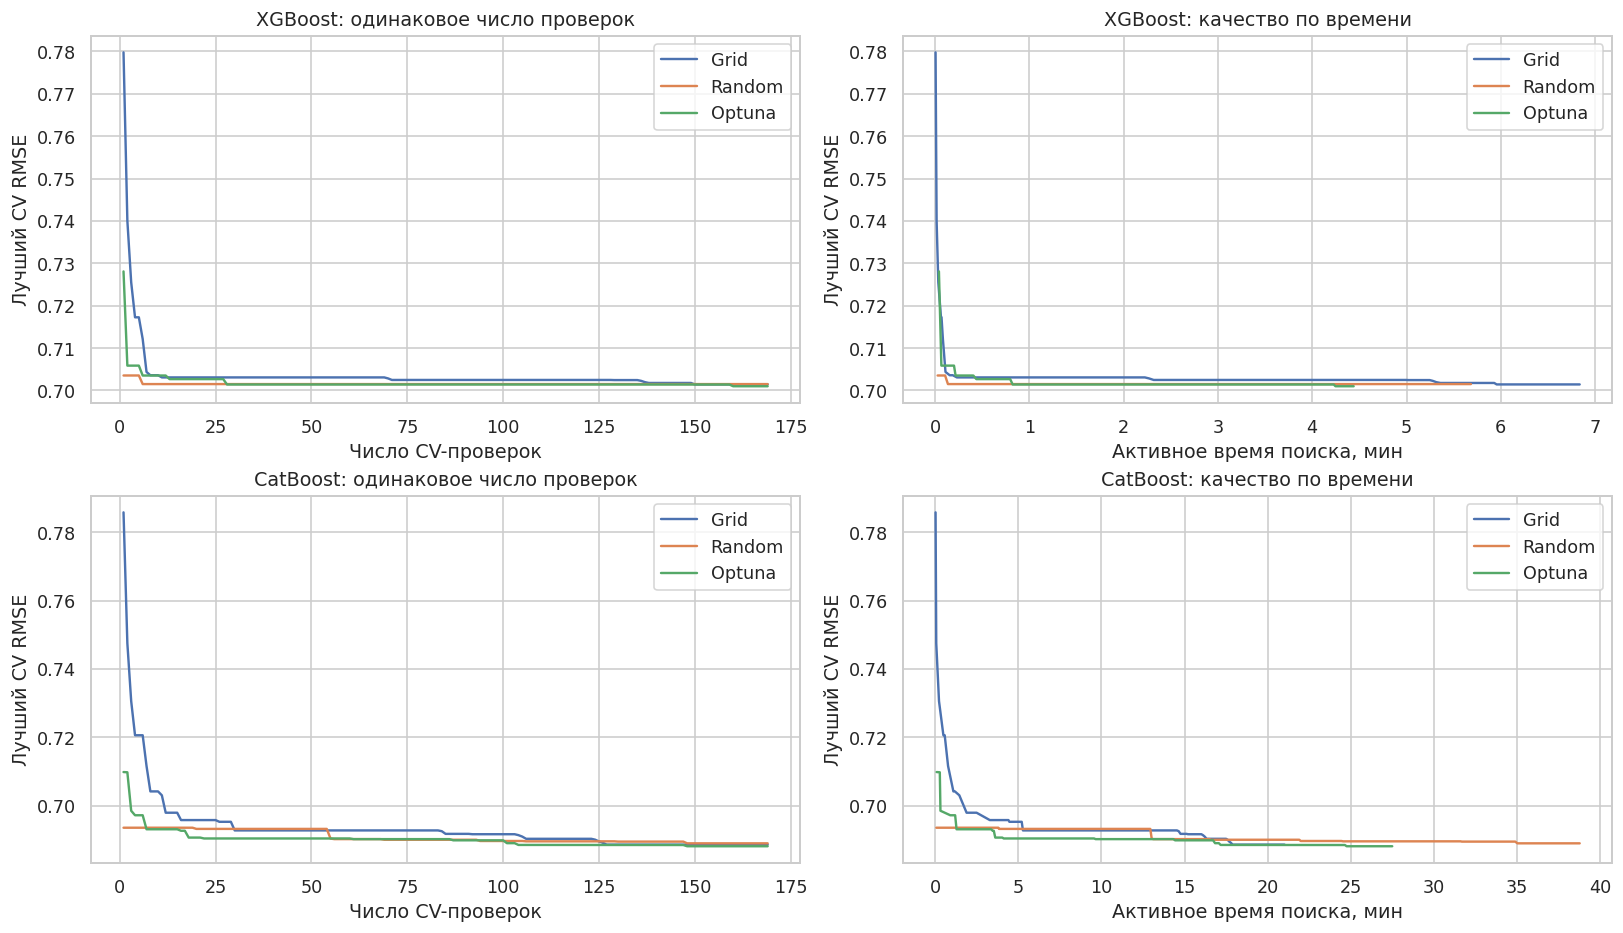

In [ ]:
comparison_rows = []
parameter_rows = []

for family, methods in search_results.items():
    for method, result in methods.items():
        best = result['best']
        params = best['params']
        unique = set()

        for row in result['rows']:
            p = row['params']
            unique.add((p['n_estimators'], p['learning_rate'], p['max_depth']))

        comparison_rows.append({
            'Модель': family,
            'Поиск': method,
            'Конфигурации': result['n_candidates'],
            'Уникальные комбинации': len(unique),
            'CV RMSE': best['cv_rmse'],
            'CV std': best['cv_std'],
            'Время, мин': result['seconds'] / 60,
        })
        parameter_rows.append({
            'Модель': family,
            'Поиск': method,
            'n_estimators': params['n_estimators'],
            'learning_rate': repr(float(params['learning_rate'])),
            'max_depth': params['max_depth'],
        })

search_comparison = pd.DataFrame(comparison_rows)
display(search_comparison.round(5))
display(pd.DataFrame(parameter_rows))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)

for row, family in enumerate(FAMILIES):
    for method, result in search_results[family].items():
        history = pd.DataFrame(result['rows'])
        best_so_far = history['cv_rmse'].cummin()
        minutes = history['search_seconds'].cumsum() / 60
        steps = np.arange(1, len(history) + 1)

        axes[row, 0].plot(steps, best_so_far, label=method)
        axes[row, 1].plot(minutes, best_so_far, label=method)

    axes[row, 0].set(
        title=f'{family}: одинаковое число проверок',
        xlabel='Число CV-проверок',
        ylabel='Лучший CV RMSE',
    )
    axes[row, 1].set(
        title=f'{family}: качество по времени',
        xlabel='Активное время поиска, мин',
        ylabel='Лучший CV RMSE',
    )
    axes[row, 0].legend()
    axes[row, 1].legend()

plt.show()

## 8. Влияние гиперпараметров

Меняем один параметр, оставляя остальные как у победителя поиска. Сравниваем train и CV; test не используем.

- Больше деревьев позволяет лучше подогнать train, но может усилить переобучение.
- Малый `learning_rate` обычно требует большего числа деревьев.
- Большая глубина позволяет описывать более сложные зависимости и запоминать шум.

Это локальные срезы: параметры могут влиять друг на друга. Полосы показывают разброс CV RMSE между folds.

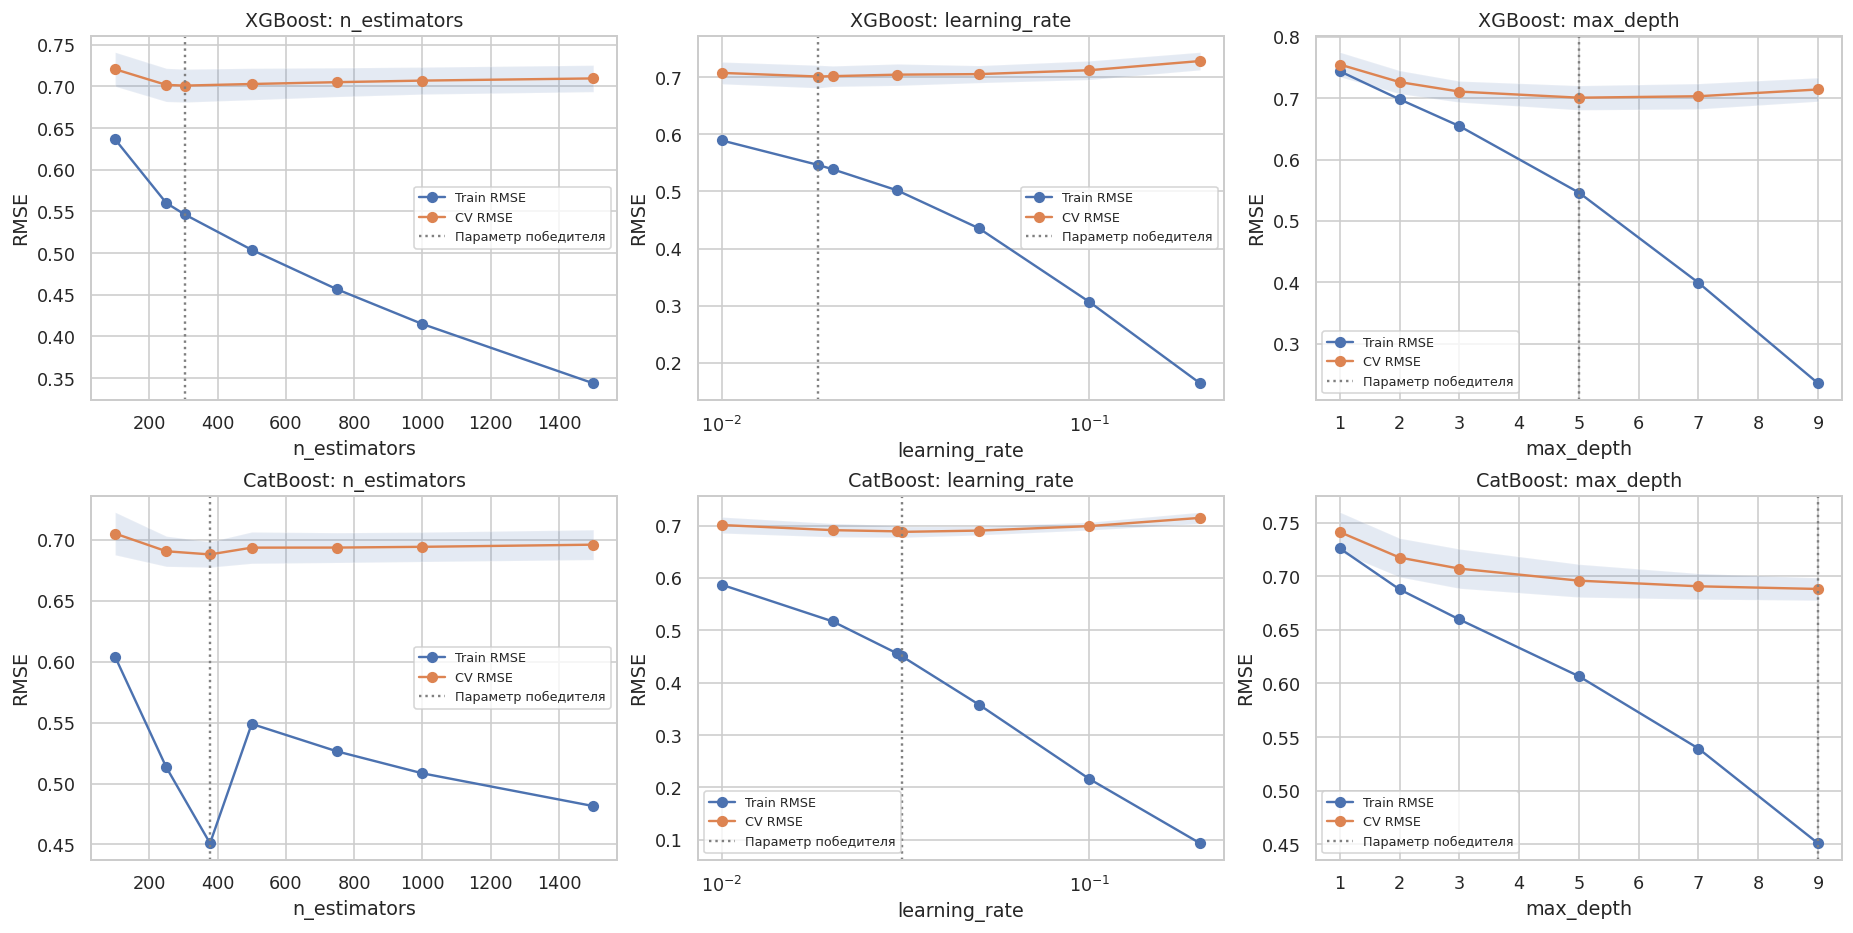

In [ ]:
search_winners = {}
for family, methods in search_results.items():
    candidates = [baseline_results[family]]
    for result in methods.values():
        candidates.append(result['best'])
    search_winners[family] = best_result(candidates)

parameter_values = {
    'n_estimators': [100, 250, 500, 750, 1000, 1500],
    'learning_rate': [0.01, 0.02, 0.03, 0.05, 0.1, 0.2],
    'max_depth': [1, 2, 3, 5, 7, 9],
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)

for row, family in enumerate(FAMILIES):
    anchor = search_winners[family]['params']

    for col, parameter in enumerate(parameter_values):
        values = sorted(set(parameter_values[parameter] + [anchor[parameter]]))
        results = []

        for value in values:
            params = anchor.copy()
            params[parameter] = value
            checkpoint = f'influence_{family}_{parameter}_{value}'
            results.append(evaluate(family, params, checkpoint=checkpoint))

        scores = pd.DataFrame(results)
        train = scores['train_rmse'].to_numpy()
        valid = scores['cv_rmse'].to_numpy()
        std = scores['cv_std'].to_numpy()
        ax = axes[row, col]

        ax.plot(values, train, 'o-', label='Train RMSE')
        ax.plot(values, valid, 'o-', label='CV RMSE')
        ax.fill_between(values, valid - std, valid + std, alpha=0.15)
        ax.axvline(
            anchor[parameter], linestyle=':', color='gray',
            label='Параметр победителя',
        )

        if parameter == 'learning_rate':
            ax.set_xscale('log')

        ax.set(title=f'{family}: {parameter}', xlabel=parameter, ylabel='RMSE')
        ax.legend(fontsize=8)

plt.show()


## 9. Кривые обучения

По оси X — размер обучающей части fold, по оси Y — train и CV RMSE. Валидационная часть неизменна, обучающие подвыборки вложены друг в друга и включают только целые группы одинаковых объектов.

| Модель | Число деревьев | `learning_rate` | Глубина |
|---|---:|---:|---:|
| Простая | 50 | 0.01 | 1 |
| Выбрана по CV | из поиска | из поиска | из поиска |
| Сложная | 1500 | 0.1 | 9 |

**Недообучение:** обе ошибки высокие и близки друг к другу. **Переобучение:** train-ошибка мала, а CV заметно выше; усложнение улучшает train и ухудшает CV. Смотрим также на изменение ошибок при росте выборки. Полосы показывают стандартное отклонение между folds.

In [ ]:
fractions = [0.2, 0.4, 0.6, 0.8, 1.0]
curve_rows = []

for family in FAMILIES:
    curve_models = {
        'Простая': {'n_estimators': 50, 'learning_rate': 0.01, 'max_depth': 1},
        'Выбрана по CV': search_winners[family]['params'],
        'Сложная': {'n_estimators': 1500, 'learning_rate': 0.1, 'max_depth': 9},
    }

    for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
        rng = np.random.default_rng(4200 + fold)
        group_order = rng.permutation(np.unique(groups_train[fit_idx]))

        for fraction in fractions:
            n_groups = max(2, int(np.ceil(fraction * len(group_order))))
            chosen_groups = group_order[:n_groups]
            mask = np.isin(groups_train[fit_idx], chosen_groups)
            subset = fit_idx[mask]

            for regime, params in curve_models.items():
                checkpoint = f'curve_{family}_{regime}_{fold}_{fraction}'
                result = load_checkpoint(checkpoint, None)
                if result is None:
                    model = make_model(family, params)
                    model.fit(X_train[subset], y_train[subset])

                    train_pred = model.predict(X_train[subset])
                    valid_pred = model.predict(X_train[valid_idx])

                    result = {
                        'family': family,
                        'regime': regime,
                        'fold': fold,
                        'fraction': fraction,
                        'n_train': len(subset),
                        'train_rmse': root_mean_squared_error(y_train[subset], train_pred),
                        'cv_rmse': root_mean_squared_error(y_train[valid_idx], valid_pred),
                    }
                    save_checkpoint(checkpoint, result)
                curve_rows.append(result)

        print(f'{family}: кривые обучения, fold {fold}/{len(cv_splits)} завершён')

curve_df = pd.DataFrame(curve_rows)
save_checkpoint('learning_curves', curve_df)


XGBoost: кривые обучения, fold 1/3 завершён
XGBoost: кривые обучения, fold 2/3 завершён
XGBoost: кривые обучения, fold 3/3 завершён
CatBoost: кривые обучения, fold 1/3 завершён
CatBoost: кривые обучения, fold 2/3 завершён
CatBoost: кривые обучения, fold 3/3 завершён


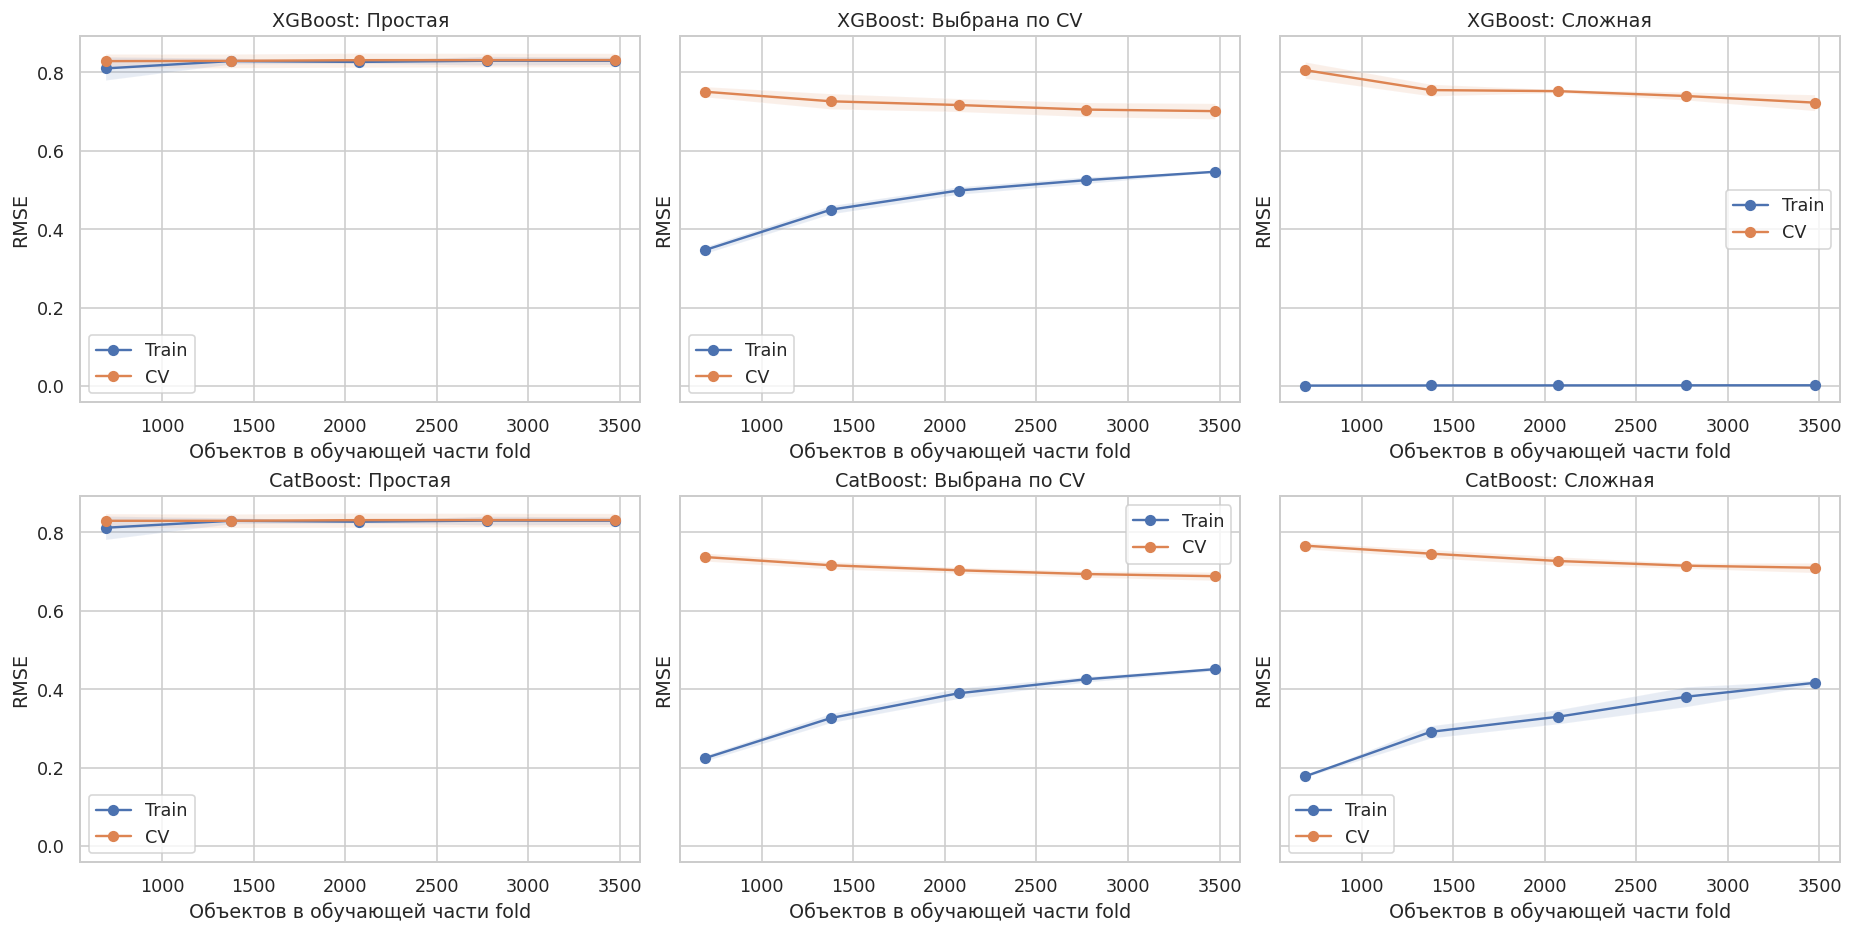

,family,regime,fraction,n_train,train_rmse,train_std,cv_rmse,cv_std
12,XGBoost,Простая,1.0,3473.33333,0.82951,0.00943,0.83129,0.01726
13,XGBoost,Выбрана по CV,1.0,3473.33333,0.54638,0.00129,0.70100,0.01978
14,XGBoost,Сложная,1.0,3473.33333,0.00192,0.00006,0.72270,0.02036
27,CatBoost,Простая,1.0,3473.33333,0.82971,0.00940,0.83121,0.01697
28,CatBoost,Выбрана по CV,1.0,3473.33333,0.45098,0.00413,0.68813,0.01047
29,CatBoost,Сложная,1.0,3473.33333,0.41615,0.00644,0.70963,0.01236


In [ ]:
curve_summary = curve_df.groupby(['family', 'regime', 'fraction'], sort=False).agg(
    n_train=('n_train', 'mean'),
    train_rmse=('train_rmse', 'mean'),
    train_std=('train_rmse', 'std'),
    cv_rmse=('cv_rmse', 'mean'),
    cv_std=('cv_rmse', 'std'),
).reset_index()

regimes = ['Простая', 'Выбрана по CV', 'Сложная']
fig, axes = plt.subplots(
    2, 3, figsize=(16, 8), sharey=True, constrained_layout=True,
)

for row, family in enumerate(FAMILIES):
    for col, regime in enumerate(regimes):
        part = curve_summary[curve_summary['family'] == family]
        part = part[part['regime'] == regime].sort_values('fraction')

        x = part['n_train'].to_numpy()
        train = part['train_rmse'].to_numpy()
        valid = part['cv_rmse'].to_numpy()
        train_std = part['train_std'].to_numpy()
        valid_std = part['cv_std'].to_numpy()
        ax = axes[row, col]

        ax.plot(x, train, 'o-', label='Train')
        ax.plot(x, valid, 'o-', label='CV')
        ax.fill_between(x, train - train_std, train + train_std, alpha=0.13)
        ax.fill_between(x, valid - valid_std, valid + valid_std, alpha=0.13)
        ax.set(
            title=f'{family}: {regime}',
            xlabel='Объектов в обучающей части fold',
            ylabel='RMSE',
        )
        ax.legend()

plt.show()
display(curve_summary[curve_summary['fraction'] == 1.0].round(5))

На полной обучающей части fold простые модели недообучаются: train RMSE около 0.830, CV RMSE около 0.831. Обе ошибки близки и выше, чем у подобранных моделей.

Для XGBoost выбранная по CV модель даёт train RMSE 0.54638 и CV RMSE 0.70100. У сложной модели train RMSE падает до 0.00192, а CV RMSE растёт до 0.72270 — это выраженное переобучение.

Для CatBoost выбранная модель даёт train RMSE 0.45098 и CV RMSE 0.68813. У сложной модели train RMSE снижается до 0.41615, а CV RMSE ухудшается до 0.70963. Усложнение также усиливает переобучение. Подобранные параметры дают лучшее CV-качество среди этих трёх режимов, хотя разрыв между train и CV сохраняется.


## 10. Выбор финалистов

Для каждой модели сравниваем baseline и победителей трёх поисков. Выбираем минимум **CV RMSE**, до просмотра test. Основная модель работы — XGBoost; CatBoost — дополнительное исследование. После оценки на test параметры не меняем.

In [ ]:
final_choices = {}
selected_by_cv = {}

for family, methods in search_results.items():
    choices = {'Baseline': baseline_results[family]}
    for method, result in methods.items():
        choices[method] = result['best']
    final_choices[family] = choices

    winner = 'Baseline'
    for method, result in choices.items():
        if result['cv_rmse'] < choices[winner]['cv_rmse']:
            winner = method

    selected_by_cv[family] = {
        'method': winner,
        'params': choices[winner]['params'],
        'cv_rmse': choices[winner]['cv_rmse'],
    }

save_checkpoint('selected_by_cv', selected_by_cv)
display(pd.DataFrame(selected_by_cv).T)
print('Финалисты зафиксированы. Далее выполняется только финальная оценка test.')


,method,params,cv_rmse
XGBoost,Optuna,"{'n_estimators': 304, 'learning_rate': 0.01824...",0.701002
CatBoost,Optuna,"{'n_estimators': 378, 'learning_rate': 0.03081...",0.688129


Финалисты зафиксированы. Далее выполняется только финальная оценка test.


## 11. Финальная оценка на test

Обучаем финалистов на всём train и считаем RMSE и MAE на одном и том же test. Для сравнения добавляем `DummyRegressor`, который предсказывает среднее значение train. Оценка на этом разбиении не гарантирует такого же результата на скрытом тесте преподавателя.

In [18]:
final_rows = []
fold_rows = []

for family, choices in final_choices.items():
    for method, result in choices.items():
        checkpoint = f'test_{family}_{method}'
        row = load_checkpoint(checkpoint, None)
        if row is None:
            model = make_model(family, result['params'])

            started = time.perf_counter()
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)
            fit_seconds = time.perf_counter() - started

            row = {
                'Модель': family,
                'Поиск': method,
                'CV RMSE': result['cv_rmse'],
                'CV std': result['cv_std'],
                'CV MAE': np.mean(result['fold_mae']),
                'Test RMSE': root_mean_squared_error(y_test, predictions),
                'Test MAE': mean_absolute_error(y_test, predictions),
                'Финальное обучение, с': fit_seconds,
                'Выбрана по CV': method == selected_by_cv[family]['method'],
            }
            save_checkpoint(checkpoint, row)
        final_rows.append(row)

        for fold in range(len(cv_splits)):
            fold_rows.append({
                'Модель': family,
                'Поиск': method,
                'Fold': fold + 1,
                'RMSE': result['fold_rmse'][fold],
                'MAE': result['fold_mae'][fold],
            })

constant_rmse = []
constant_mae = []

for fit_idx, valid_idx in cv_splits:
    dummy = DummyRegressor(strategy='mean')
    dummy.fit(X_train[fit_idx], y_train[fit_idx])
    predictions = dummy.predict(X_train[valid_idx])

    constant_rmse.append(root_mean_squared_error(y_train[valid_idx], predictions))
    constant_mae.append(mean_absolute_error(y_train[valid_idx], predictions))

dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
predictions = dummy.predict(X_test)

final_rows.append({
    'Модель': 'Константа',
    'Поиск': 'Среднее train',
    'CV RMSE': np.mean(constant_rmse),
    'CV std': np.std(constant_rmse, ddof=1),
    'CV MAE': np.mean(constant_mae),
    'Test RMSE': root_mean_squared_error(y_test, predictions),
    'Test MAE': mean_absolute_error(y_test, predictions),
    'Выбрана по CV': False,
})

final_table = pd.DataFrame(final_rows)
fold_table = pd.DataFrame(fold_rows)
display(final_table.round(5))
save_checkpoint('final_results', final_table)
save_checkpoint('cv_fold_results', fold_table)


,Модель,Поиск,CV RMSE,CV std,CV MAE,Test RMSE,Test MAE,"Финальное обучение, с",Выбрана по CV
0,XGBoost,Baseline,0.70467,0.01595,0.55064,0.67341,0.52147,0.10455,False
1,XGBoost,Grid,0.70143,0.01841,0.54649,0.66739,0.51572,0.52399,False
2,XGBoost,Random,0.70151,0.01936,0.54625,0.66740,0.51674,0.59738,False
3,XGBoost,Optuna,0.70100,0.01978,0.54641,0.66881,0.51803,0.37512,True
4,CatBoost,Baseline,0.70937,0.02008,0.55747,0.67816,0.53201,0.26804,False
5,CatBoost,Grid,0.68860,0.01054,0.53457,0.65650,0.51070,2.37836,False
6,CatBoost,Random,0.68898,0.00942,0.53421,0.65232,0.50683,2.70103,False
7,CatBoost,Optuna,0.68813,0.01047,0.53427,0.65274,0.50826,2.16853,True
8,Константа,Среднее train,0.87817,0.01461,0.68849,0.85236,0.67950,NaN,False


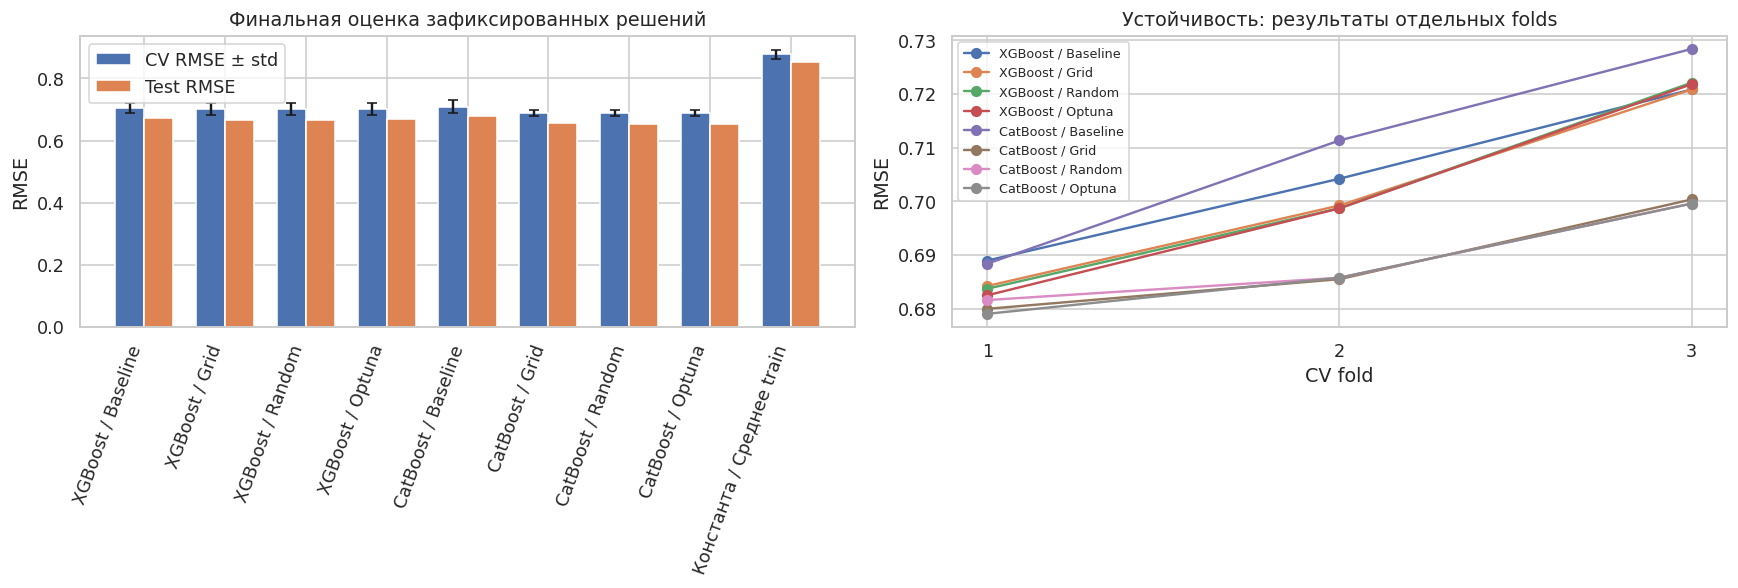

Fold                     1        2        3
Модель   Поиск                              
CatBoost Baseline  0.68838  0.71134  0.72840
         Grid      0.67997  0.68549  0.70035
         Optuna    0.67904  0.68578  0.69958
         Random    0.68160  0.68575  0.69959
XGBoost  Baseline  0.68896  0.70421  0.72085
         Grid      0.68422  0.69923  0.72085
         Optuna    0.68248  0.69869  0.72183
         Random    0.68371  0.69870  0.72212

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
labels = final_table['Модель'] + ' / ' + final_table['Поиск']
x = np.arange(len(final_table))

axes[0].bar(
    x - 0.18, final_table['CV RMSE'], width=0.36,
    yerr=final_table['CV std'], capsize=3, label='CV RMSE ± std',
)
axes[0].bar(
    x + 0.18, final_table['Test RMSE'], width=0.36, label='Test RMSE',
)
axes[0].set_xticks(x, labels, rotation=70, ha='right')
axes[0].set(ylabel='RMSE', title='Финальная оценка зафиксированных решений')
axes[0].legend()

for family, choices in final_choices.items():
    for method in choices:
        part = fold_table[fold_table['Модель'] == family]
        part = part[part['Поиск'] == method]
        axes[1].plot(
            part['Fold'], part['RMSE'], 'o-', label=f'{family} / {method}',
        )

axes[1].set(
    xticks=np.arange(1, len(cv_splits) + 1),
    xlabel='CV fold',
    ylabel='RMSE',
    title='Устойчивость: результаты отдельных folds',
)
axes[1].legend(fontsize=8)
plt.show()

fold_comparison = fold_table.pivot(
    index=['Модель', 'Поиск'], columns='Fold', values='RMSE',
)
display(fold_comparison.round(5))

## 12. Выводы

Выбор параметров сделан по CV. Разброс между folds помогает оценить устойчивость, а test показывает качество уже выбранных решений на отложенных данных. Улучшение CV не обязано повторяться на test: выборки конечны, а минимум CV выбран среди множества кандидатов.

Ниже приведены выводы по выполненному запуску. Близкие результаты не доказывают универсального превосходства модели или метода поиска.

На объединённом датасете из 6497 красных и белых вин каждый из трёх методов проверил 64 широкие и 105 уточняющих конфигураций для каждой модели. Всего выполнено 1014 CV-проверок конфигураций, каждая на трёх folds.

Для XGBoost по CV выбрана Optuna: 304 дерева, learning_rate ≈ 0.01824, глубина 5. CV RMSE = 0.70100, Test RMSE = 0.66881, Test MAE = 0.51803. У baseline Test RMSE = 0.67341, поэтому подбор немного улучшил качество на этом test.

Для CatBoost по CV также выбрана Optuna: 378 деревьев, learning_rate ≈ 0.03082, глубина 9. CV RMSE = 0.68813, Test RMSE = 0.65274, Test MAE = 0.50826. У baseline Test RMSE = 0.67816. В этом эксперименте CatBoost показал меньшую ошибку, чем XGBoost; обе модели лучше константы с Test RMSE = 0.85236.

Результаты трёх методов поиска близки: разница лучшего и худшего CV RMSE составляет около 0.00051 для XGBoost и 0.00085 для CatBoost. Optuna дала минимальный CV RMSE у обеих моделей. Активное время поиска составило 4.44 минуты для XGBoost и 27.49 минуты для CatBoost; Grid и Random заняли соответственно 6.84 и 5.68 минуты для XGBoost, 21.01 и 38.77 минуты для CatBoost. Запись чекпоинтов в эти измерения не входит.

На test минимальный RMSE у XGBoost Grid (0.66739) и CatBoost Random (0.65232), но финалистами остаются решения Optuna, выбранные заранее по CV. После просмотра test параметры не меняем. Один запуск на одном разбиении не доказывает универсального превосходства метода.

Кривые обучения показывают недообучение простых моделей и переобучение слишком сложных. Подбор параметров улучшил баланс между train и CV, сохранив заметный разрыв ошибок.
